# 10. Tổng hợp kết quả các thuật toán cho chương 4

Một notebook gom số liệu của mọi thực nghiệm trong đề cương thành bảng và biểu đồ để đưa vào báo cáo:
SM-2 / FSRS (mục 4.4: so sánh trên cùng lịch sử ôn tập), Genetic Algorithm (trước / sau tối ưu), VIP (SM-2 nguyên bản
vs SM-2 + VIP, nhóm từ dễ nhầm thị giác), Smart Distractor (ngẫu nhiên vs thông minh), Proximity Search, và các quyết
định chọn cấu hình. Geofence và realtime ở notebook 09.

**Nguồn số liệu:** `AI/report/experiments/production.json` (lấy bằng `run-experiments.bat`: chạy mọi thực nghiệm trên
server lingoprism.id.vn, GA chỉ đo, không ghi tham số mới vào hệ thống). Thực nghiệm nào production chưa có thì lấy lần
chạy mới nhất trong database của máy này. Mỗi bảng ghi rõ nguồn.

> **Lưu ý khi viết báo cáo:** SM-2/FSRS, GA và phần dự đoán của benchmark học trên *lịch sử ôn tập trong database*.
> Bảng 10.0 cho biết bao nhiêu lượt ôn là của người dùng thật, bao nhiêu của học viên mẫu (`seed_demo_activity`). VIP và
> phần lịch ôn của benchmark chạy trên người học mô phỏng (mô hình quên), nên không phụ thuộc dữ liệu thật.

> **Cách chạy:** kernel **LingoPrism (BE venv)** → *Run All*. Hình lưu ở `AI/notebooks/figures/10_*.png`, bảng Markdown
> ở `AI/report/experiments/bang_tong_hop.md`.

In [1]:
# Khởi tạo: nạp Django của BE/ (database + mã thật của server) và matplotlib
import pathlib, sys
_here = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "AI/notebooks/lingoprism_setup.py").exists())
sys.path.insert(0, str(_here / "AI/notebooks"))
from lingoprism_setup import ROOT, init, save, table
init()

import json
import numpy as np
import matplotlib.pyplot as plt
from apps.algorithms.experiments import latest

REPORT = ROOT / "AI/report/experiments"
REPORT.mkdir(parents=True, exist_ok=True)
prod_file = REPORT / "production.json"
prod = json.loads(prod_file.read_text(encoding="utf-8")) if prod_file.exists() else {}
local = latest()
RUNS, SOURCE = {}, {}
for kind in ("srs", "ga", "vip", "distractor", "proximity", "benchmark"):
    if kind in prod.get("runs", {}):
        RUNS[kind], SOURCE[kind] = prod["runs"][kind], "production"
    elif kind in local:
        RUNS[kind], SOURCE[kind] = local[kind], "máy phát triển"
R = {k: v["results"] for k, v in RUNS.items()}
table([{"thực nghiệm": k, "nguồn": SOURCE[k], "chạy lúc": str(RUNS[k]["created_at"])[:16], "thời gian (s)": RUNS[k]["duration_s"]} for k in RUNS])

Django OK – config.settings.dev | hình lưu ở D:\kicuoi\doantotnghiep\SnapLingua-main\AI\notebooks\figures
thực nghiệm  nguồn           chạy lúc          thời gian (s)
-----------  --------------  ----------------  -------------
srs          máy phát triển  2026-10-16 00:35  0.1200       
ga           máy phát triển  2026-10-16 00:35  10.7900      
vip          máy phát triển  2026-10-19 06:03  1.8500       
distractor   máy phát triển  2026-10-19 06:04  36.1100      
proximity    máy phát triển  2026-10-19 06:04  1.6500       
benchmark    máy phát triển  2026-10-19 06:04  94.3600      


## 10.0 Dữ liệu dùng cho các thực nghiệm

In [2]:
data = prod.get("data")
if data:
    demo = data["review_logs"] - data["review_logs_real_users"]
    table([{"chỉ số": "lượt ôn (lần trả lời đầu trong phiên)", "giá trị": data["review_logs"]},
           {"chỉ số": "  của người dùng thật", "giá trị": data["review_logs_real_users"]},
           {"chỉ số": "  của học viên mẫu / tài khoản thử", "giá trị": demo},
           {"chỉ số": "người học thật", "giá trị": data["real_learners"]},
           {"chỉ số": "người học thật đã ôn ít nhất 1 lần", "giá trị": data["real_learners_with_reviews"]}])
    share = data["review_logs_real_users"] / max(data["review_logs"], 1)
    DATA_NOTE = (f"Lịch sử ôn trên production: {data['review_logs']} lượt, trong đó {share:.0%} của "
                 f"{data['real_learners_with_reviews']} người dùng thật, phần còn lại của học viên mẫu.")
else:
    DATA_NOTE = ("Chưa có số liệu đầy đủ từ production (chạy run-experiments.bat không kèm quick): SM-2/FSRS/GA "
                 "dưới đây là của học viên mẫu trên máy phát triển.")
print(DATA_NOTE)

Chưa có số liệu đầy đủ từ production (chạy run-experiments.bat không kèm quick): SM-2/FSRS/GA dưới đây là của học viên mẫu trên máy phát triển.


## 10.1 SM-2 vs FSRS: dự đoán nhớ / quên trên cùng lịch sử ôn tập

Mỗi mô hình phát lại lịch sử ôn của từng thẻ và dự đoán xác suất nhớ trước mỗi lần ôn. Log-loss và RMSE càng thấp càng
tốt, AUC và accuracy càng cao càng tốt. Leitner là cách cũ của SnapLingua, FSRS+GA là FSRS với tham số do GA tìm.

3456 thẻ, 11883 lượt ôn – nguồn: máy phát triển
mô hình        log_loss  rmse    auc     accuracy
-------------  --------  ------  ------  --------
Leitner (cũ)   0.6779    0.4790  0.6757  0.6853  
SM-2           0.6337    0.4649  0.6354  0.6838  
FSRS mặc định  0.6986    0.4831  0.6955  0.6829  
FSRS + GA      0.5249    0.4169  0.7628  0.7520  


WindowsPath('D:/kicuoi/doantotnghiep/SnapLingua-main/AI/notebooks/figures/10_srs_so_sanh.png')

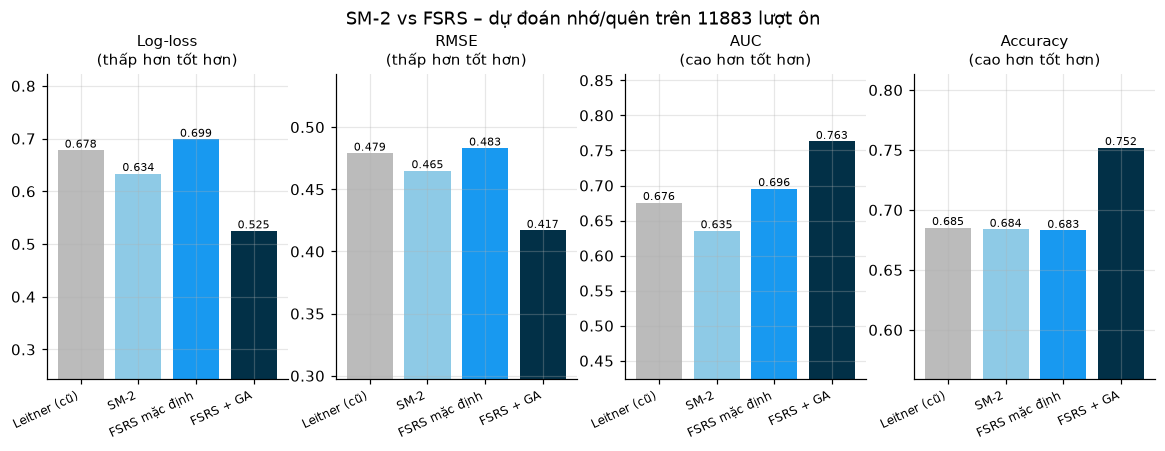

In [3]:
LABEL = {"leitner": "Leitner (cũ)", "sm2": "SM-2", "fsrs": "FSRS mặc định", "fsrs_default": "FSRS mặc định", "fsrs_ga": "FSRS + GA"}
srs = R["srs"]
order = [k for k in ("leitner", "sm2", "fsrs", "fsrs_ga") if k in srs["models"]]
srs_rows = [{"mô hình": LABEL[k], **{m: srs["models"][k][m] for m in ("log_loss", "rmse", "auc", "accuracy")}} for k in order]
print(f"{srs['cards']} thẻ, {srs['reviews']} lượt ôn – nguồn: {SOURCE['srs']}")
table(srs_rows)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
cols = ["#bbbbbb", "#8ecae6", "#1899f0", "#023047"]
for ax, (m, title, better) in zip(axes, [("log_loss", "Log-loss", "thấp hơn tốt hơn"), ("rmse", "RMSE", "thấp hơn tốt hơn"),
                                          ("auc", "AUC", "cao hơn tốt hơn"), ("accuracy", "Accuracy", "cao hơn tốt hơn")]):
    vals = [srs["models"][k][m] for k in order]
    bars = ax.bar(range(len(order)), vals, color=cols[:len(order)])
    ax.bar_label(bars, fmt="%.3f", fontsize=7)
    ax.set_xticks(range(len(order)), [LABEL[k] for k in order], rotation=25, ha="right", fontsize=8)
    ax.set_title(f"{title}\n({better})", fontsize=10)
    lo, hi = min(vals), max(vals)
    ax.set_ylim(max(0, lo - (hi - lo) * 1.5 - 0.02), hi + (hi - lo) * 0.6 + 0.02)
fig.suptitle(f"SM-2 vs FSRS – dự đoán nhớ/quên trên {srs['reviews']} lượt ôn", y=1.04)
save(fig, "10_srs_so_sanh")

## 10.2 Genetic Algorithm: tối ưu 17 tham số FSRS

Quần thể bộ tham số, chọn lọc tournament, lai ghép BLX-α, đột biến Gauss, giữ 2 cá thể tốt nhất. Hàm thích nghi =
−log-loss trên thẻ huấn luyện; kết quả được kiểm tra trên thẻ chưa dùng khi tìm kiếm.

Quần thể 24, 25 thế hệ, 2765 thẻ huấn luyện / 691 thẻ kiểm tra – nguồn: máy phát triển
mô hình        log_loss  rmse    auc     accuracy
-------------  --------  ------  ------  --------
SM-2           0.6319    0.4652  0.6357  0.6881  
FSRS mặc định  0.7086    0.4873  0.6909  0.6758  
FSRS + GA      0.5210    0.4147  0.7713  0.7688  

GA giảm log-loss 26.5% so với tham số FSRS mặc định (trên thẻ kiểm tra).


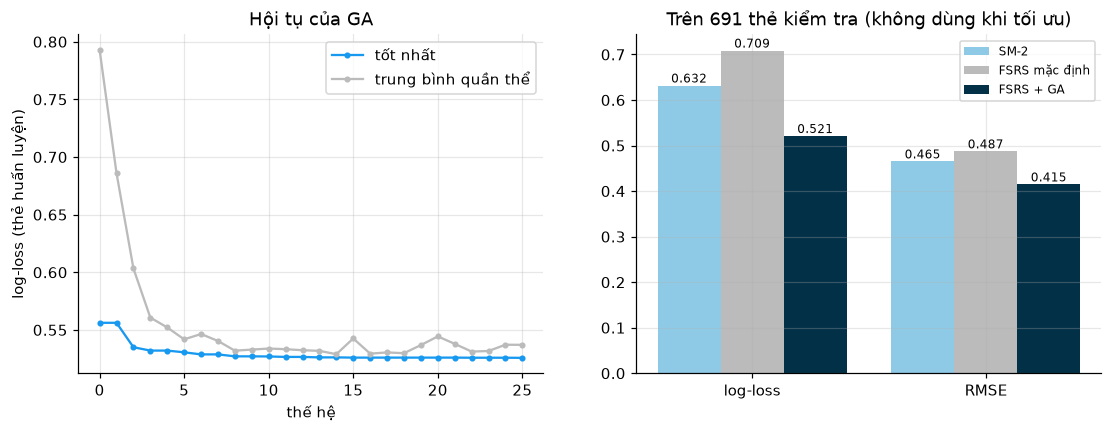

In [4]:
ga = R["ga"]
hist = ga["history"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot([h["generation"] for h in hist], [h["best"] for h in hist], marker="o", ms=3, label="tốt nhất", color="#1899f0")
axes[0].plot([h["generation"] for h in hist], [h["mean"] for h in hist], marker="o", ms=3, label="trung bình quần thể", color="#bbbbbb")
axes[0].set_xlabel("thế hệ"); axes[0].set_ylabel("log-loss (thẻ huấn luyện)"); axes[0].legend(); axes[0].set_title("Hội tụ của GA")
test = ga["test"]
keys = [k for k in ("sm2", "fsrs_default", "fsrs_ga") if k in test]
x = np.arange(2)
for i, k in enumerate(keys):
    vals = [test[k]["log_loss"], test[k]["rmse"]]
    bars = axes[1].bar(x + (i - 1) * 0.27, vals, 0.27, label=LABEL[k], color=["#8ecae6", "#bbbbbb", "#023047"][i])
    axes[1].bar_label(bars, fmt="%.3f", fontsize=8)
axes[1].set_xticks(x, ["log-loss", "RMSE"]); axes[1].legend(fontsize=8)
axes[1].set_title(f"Trên {ga['test_cards']} thẻ kiểm tra (không dùng khi tối ưu)")
save(fig, "10_ga")
ga_rows = [{"mô hình": LABEL[k], **{m: test[k][m] for m in ("log_loss", "rmse", "auc", "accuracy")}} for k in keys]
print(f"Quần thể {ga['population']}, {ga['generations']} thế hệ, {ga['train_cards']} thẻ huấn luyện / {ga['test_cards']} thẻ kiểm tra – nguồn: {SOURCE['ga']}")
table(ga_rows)
impr = 1 - test["fsrs_ga"]["log_loss"] / test["fsrs_default"]["log_loss"]
print(f"\nGA giảm log-loss {impr:.1%} so với tham số FSRS mặc định (trên thẻ kiểm tra).")

## 10.3 VIP: SM-2 / FSRS có và không có ưu tiên theo nhầm lẫn thị giác

Người học mô phỏng ôn tối đa 25 từ mỗi ngày. Baseline lấy từ đến hạn theo ngày; VIP xếp theo điểm ưu tiên (nguy cơ quên,
độ khó, độ tin cậy nhận diện, mức nhầm lẫn thị giác); VIP hybrid giữ thứ tự theo hạn nhưng đẩy từ dễ nhầm lên sớm.

12 người học × 60 ngày, 1190 từ (51 từ dễ nhầm thị giác) – nguồn: máy phát triển
lịch ôn  thứ tự               nhớ chung  nhớ từ dễ nhầm  lượt ôn / người
-------  -------------------  ---------  --------------  ---------------
SM-2     theo hạn (baseline)  0.4449     0.2568          1377.8000      
SM-2     VIP                  0.3192     0.6212          1377.2000      
SM-2     VIP hybrid           0.4398     0.3053          1376.3000      
FSRS     theo hạn (baseline)  0.4537     0.3083          1376.5000      
FSRS     VIP                  0.3778     0.7398          1376.4000      
FSRS     VIP hybrid           0.4745     0.3130          1375.5000      
Leitner  theo hạn (baseline)  0.3684     0.1949          1345.6000      



SM-2 + VIP: từ dễ nhầm 25.7% → 62.1%, nhớ chung 44.5% → 31.9%


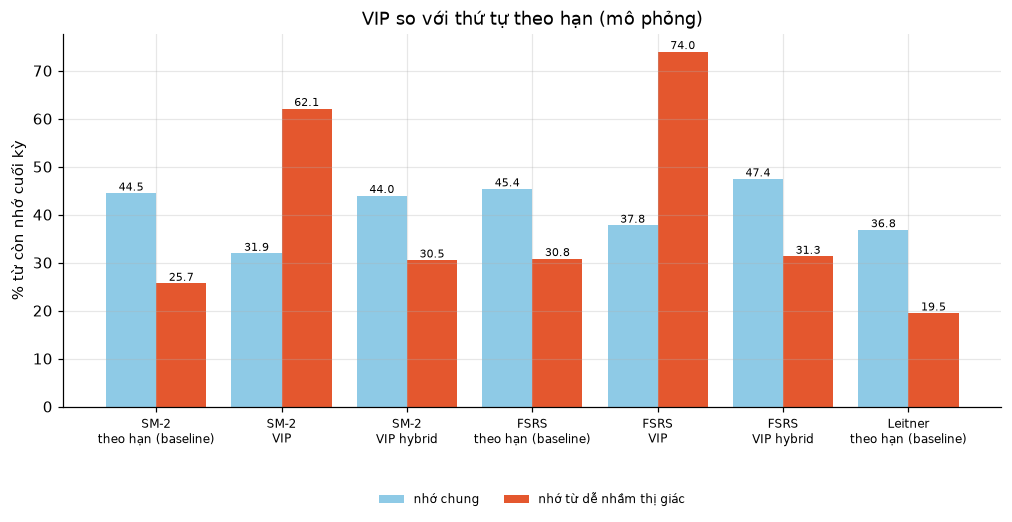

In [5]:
vip = R["vip"]
PRIO = {"due": "theo hạn (baseline)", "vip": "VIP", "vip_hybrid": "VIP hybrid"}
vip_rows = [{"lịch ôn": {"sm2": "SM-2", "fsrs": "FSRS", "leitner": "Leitner"}.get(r["scheduler"], r["scheduler"]),
             "thứ tự": PRIO.get(r.get("priority", "due"), r.get("priority")),
             "nhớ chung": r["recall_all"], "nhớ từ dễ nhầm": r["recall_confusable"],
             "lượt ôn / người": r["reviews_per_learner"]} for r in vip["rows"]]
s = vip["setup"]
print(f"{s['learners']} người học × {s['days']} ngày, {vip['words']} từ ({vip['confusable_words']} từ dễ nhầm thị giác) – nguồn: {SOURCE['vip']}")
table(vip_rows)

labels = [f"{r['lịch ôn']}\n{r['thứ tự']}" for r in vip_rows]
x = np.arange(len(vip_rows))
fig, ax = plt.subplots(figsize=(11, 4.4))
b1 = ax.bar(x - 0.2, [r["nhớ chung"] * 100 for r in vip_rows], 0.4, label="nhớ chung", color="#8ecae6")
b2 = ax.bar(x + 0.2, [r["nhớ từ dễ nhầm"] * 100 for r in vip_rows], 0.4, label="nhớ từ dễ nhầm thị giác", color="#e4572e")
ax.bar_label(b1, fmt="%.1f", fontsize=7); ax.bar_label(b2, fmt="%.1f", fontsize=7)
ax.set_xticks(x, labels, fontsize=8); ax.set_ylabel("% từ còn nhớ cuối kỳ")
ax.legend(fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
ax.set_title("VIP so với thứ tự theo hạn (mô phỏng)")
save(fig, "10_vip")
base = next(r for r in vip["rows"] if r["scheduler"] == "sm2" and r.get("priority") == "due")
best = max((r for r in vip["rows"] if r["scheduler"] == "sm2" and r.get("priority") != "due"), key=lambda r: r["recall_confusable"])
print(f"\nSM-2 + {PRIO[best['priority']]}: từ dễ nhầm {base['recall_confusable']:.1%} → {best['recall_confusable']:.1%}, "
      f"nhớ chung {base['recall_all']:.1%} → {best['recall_all']:.1%}")

## 10.4 Smart Distractor vs chọn ngẫu nhiên

Tương đồng ngữ nghĩa = cosine trung bình giữa đáp án đúng và đáp án nhiễu (Word2Vec tự cài): càng cao thì đáp án nhiễu
càng "đánh lừa" tốt. Không hợp lệ = đáp án nhiễu cùng nghĩa với đáp án đúng (câu hỏi có hai đáp án đúng).

250 từ – nguồn: máy phát triển
phương pháp             số đáp án nhiễu  tương đồng ngữ nghĩa  cùng từ loại  không hợp lệ
----------------------  ---------------  --------------------  ------------  ------------
ngẫu nhiên cùng chủ đề  750              0.4114                100%          0.0%        
Smart Distractor        750              0.6128                100%          0.0%        

từ                ngẫu nhiên                       Smart                            
----------------  -------------------------------  ---------------------------------
luyện tập         thay đổi, cười, bán              học, tập thể dục, nâng cao       
muối              bánh vòng, mật ong, bánh mì kẹp  đường, canh, bơ                  
con chim          con chó, con chuột, con rùa      động vật, con nhện, con mèo      
mất ngủ           vệ sinh, vắc xin, vitamin        trầm cảm, triệu chứng, bệnh      
mười ba           bốn mươi, một, một số            ba mươi, mười tám, mười bốn      
mùa hè       

WindowsPath('D:/kicuoi/doantotnghiep/SnapLingua-main/AI/notebooks/figures/10_distractor.png')

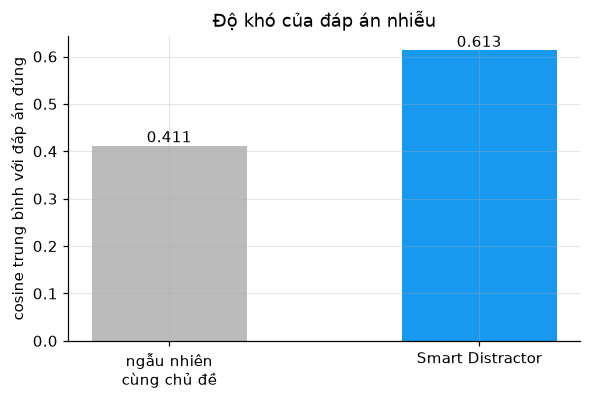

In [6]:
dis = R["distractor"]
st = dis["stats"]
dis_rows = [{"phương pháp": {"random": "ngẫu nhiên cùng chủ đề", "smart": "Smart Distractor"}[k], "số đáp án nhiễu": st[k]["distractors"],
             "tương đồng ngữ nghĩa": st[k]["mean_similarity"], "cùng từ loại": f"{st[k]['same_pos_rate']:.0%}",
             "không hợp lệ": f"{st[k]['invalid_rate']:.1%}"} for k in ("random", "smart")]
print(f"{dis['words']} từ – nguồn: {SOURCE['distractor']}")
table(dis_rows)
print()
table([{"từ": e["word"], "ngẫu nhiên": ", ".join(map(str, e["random"])), "Smart": ", ".join(map(str, e["smart"]))} for e in dis["examples"][:8]])

fig, ax = plt.subplots(figsize=(6, 3.6))
bars = ax.bar(["ngẫu nhiên\ncùng chủ đề", "Smart Distractor"], [st["random"]["mean_similarity"], st["smart"]["mean_similarity"]],
              color=["#bbbbbb", "#1899f0"], width=0.5)
ax.bar_label(bars, fmt="%.3f")
ax.set_ylabel("cosine trung bình với đáp án đúng"); ax.set_title("Độ khó của đáp án nhiễu")
save(fig, "10_distractor")

## 10.5 Proximity Search: chỉ mục lưới tự cài

30 POI, 500 truy vấn – nguồn: máy phát triển
phương pháp                ms / truy vấn  khớp kết quả           
-------------------------  -------------  -----------------------
lưới + Haversine (tự cài)  0.0153         500/500 với brute force
brute force                0.0172         –                      
PostgreSQL earthdistance   1.4852         499/500 với lưới       

pois   grid_ms  speedup   brute_ms
-----  -------  --------  --------
1000   0.0030   257.7000  0.8300  
10000  0.0270   391.7000  10.7580 
50000  0.0740   414.6000  30.7720 


WindowsPath('D:/kicuoi/doantotnghiep/SnapLingua-main/AI/notebooks/figures/10_proximity.png')

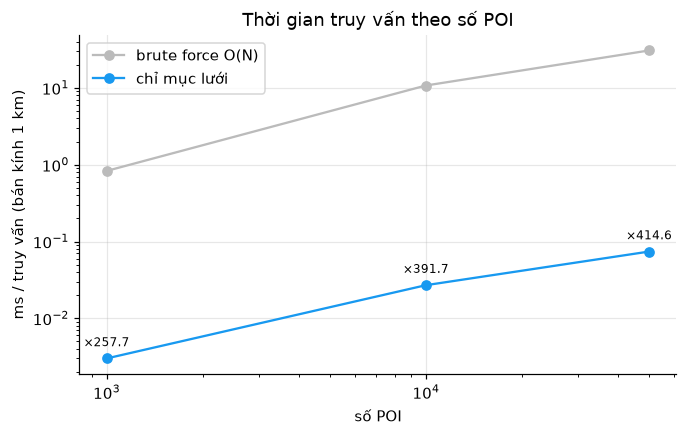

In [7]:
px = R["proximity"]
print(f"{px['pois']} POI, {px['queries']} truy vấn – nguồn: {SOURCE['proximity']}")
prox_rows = [{"phương pháp": "lưới + Haversine (tự cài)", "ms / truy vấn": px["grid_ms"], "khớp kết quả": px["grid_equals_brute"] + " với brute force"},
             {"phương pháp": "brute force", "ms / truy vấn": px["brute_ms"], "khớp kết quả": "–"},
             {"phương pháp": "PostgreSQL earthdistance", "ms / truy vấn": px["postgres_ms"], "khớp kết quả": px["grid_vs_postgres_ids"] + " với lưới"}]
table(prox_rows)
print()
table(px["scaling"])
sc = px["scaling"]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot([s["pois"] for s in sc], [s["brute_ms"] for s in sc], marker="o", label="brute force O(N)", color="#bbbbbb")
ax.plot([s["pois"] for s in sc], [s["grid_ms"] for s in sc], marker="o", label="chỉ mục lưới", color="#1899f0")
for s in sc:
    ax.annotate(f"×{s['speedup']}", (s["pois"], s["grid_ms"]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("số POI"); ax.set_ylabel("ms / truy vấn (bán kính 1 km)")
ax.legend(); ax.set_title("Thời gian truy vấn theo số POI")
save(fig, "10_proximity")

## 10.6 Quyết định chọn cấu hình (benchmark)

Benchmark thử mọi tổ hợp lịch ôn × thứ tự ôn × tham số, chọn theo quy tắc nêu rõ, rồi kiểm tra lại trên nhóm người học mới
(không dùng khi chọn).

In [8]:
bm = R["benchmark"]
print("Quy tắc:", bm["rule"]); print("Nguồn:", SOURCE["benchmark"]); print()
dec_rows = [{"quyết định": d["decision"], "chọn": d["chosen"], "bằng chứng": d["evidence"]} for d in bm["decisions"]]
table(dec_rows)
ch, bl = bm["schedule"]["chosen"], bm["schedule"]["baseline"]
print(f"\nSo với baseline (SM-2, theo hạn): nhớ chung {bl['recall_all']:.1%} → {ch['recall_all']:.1%}, "
      f"từ dễ nhầm {bl['recall_confusable']:.1%} → {ch['recall_confusable']:.1%}")
val = bm["schedule"]["validation"]
table([{"tổ hợp": v["label"], "nhớ chung": f"{v['recall_all']:.1%}", "từ dễ nhầm": f"{v['recall_confusable']:.1%}"} for v in val])

Quy tắc: Chọn tổ hợp giữ từ dễ nhầm tốt nhất trong số các tổ hợp có tỉ lệ nhớ chung không thấp hơn tổ hợp tốt nhất quá 2%.
Nguồn: máy phát triển

quyết định                               chọn            bằng chứng                                             
---------------------------------------  --------------  -------------------------------------------------------
Lịch ôn                                  FSRS+GA r=0.9   nhớ chung 47.5%, từ dễ nhầm 36.1% (mô phỏng)           
Thứ tự ôn                                VIP lai 1 ngày  trong ngưỡng −2% nhớ chung, giữ từ dễ nhầm tốt nhất    
Đáp án nhiễu                             smart           độ gần nghĩa 0.4114 → 0.6128, đáp án nhiễu cũng đúng 0%
Tìm điểm gần                             grid            đúng 500/500 so với brute force, 0.0153 ms vs 1.4852 ms
Nhận diện ảnh (lingoprism-yolov10n)      combined        coco top-1 87%, trained top-1 50%, combined top-1 81%  
Nhận diện ảnh (yolov8s-oiv7-lingoprism)  combined        coco t

## 10.7 Bảng Markdown cho báo cáo

In [9]:
def mdt(rows):
    cols = list(rows[0])
    fmt = lambda v: f"{v:.4f}" if isinstance(v, float) else str(v)
    out = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    out += ["| " + " | ".join(fmt(r[c]) for c in cols) + " |" for r in rows]
    return "\n".join(out)

pct = lambda rows, keys: [{k: (f"{v:.1%}" if k in keys and isinstance(v, float) else v) for k, v in r.items()} for r in rows]
parts = ["# Kết quả các thuật toán", DATA_NOTE,
         f"## Bảng 1. SM-2 vs FSRS – dự đoán nhớ/quên ({srs['reviews']} lượt ôn, nguồn: {SOURCE['srs']})", mdt(srs_rows),
         f"## Bảng 2. Genetic Algorithm – trên {ga['test_cards']} thẻ kiểm tra (nguồn: {SOURCE['ga']})", mdt(ga_rows),
         f"GA giảm log-loss {impr:.1%} so với tham số FSRS mặc định.",
         f"## Bảng 3. VIP – mô phỏng {vip['setup']['learners']} người học × {vip['setup']['days']} ngày (nguồn: {SOURCE['vip']})",
         mdt(pct(vip_rows, {"nhớ chung", "nhớ từ dễ nhầm"})),
         f"## Bảng 4. Smart Distractor – {dis['words']} từ (nguồn: {SOURCE['distractor']})", mdt(dis_rows),
         f"## Bảng 5. Proximity Search – {px['pois']} POI (nguồn: {SOURCE['proximity']})", mdt(prox_rows), mdt(px["scaling"]),
         f"## Bảng 6. Quyết định chọn cấu hình (nguồn: {SOURCE['benchmark']})", mdt(dec_rows),
         "Hình: `AI/notebooks/figures/10_srs_so_sanh.png`, `10_ga.png`, `10_vip.png`, `10_distractor.png`, `10_proximity.png`. "
         "Geofence và realtime: `bang_ket_qua.md` (notebook 09)."]
path = REPORT / "bang_tong_hop.md"
path.write_text("\n\n".join(parts) + "\n", encoding="utf-8")
print("Đã ghi", path)

Đã ghi D:\kicuoi\doantotnghiep\SnapLingua-main\AI\report\experiments\bang_tong_hop.md
